<center><p float="center">
  <img src="https://upload.wikimedia.org/wikipedia/commons/e/e9/4_RGB_McCombs_School_Brand_Branded.png" width="300" height="100"/>
  <img src="https://mma.prnewswire.com/media/1458111/Great_Learning_Logo.jpg?p=facebook" width="200" height="100"/>
</p></center>

<center><font size=10>Artificial Intelligence and Machine Learning</font></center>
<center><font size=6>Ensemble Techniques and Model Tuning</font></center>

<center><img src="https://images.pexels.com/photos/7235894/pexels-photo-7235894.jpeg?auto=compress&cs=tinysrgb&w=1260&h=750&dpr=2" width="800" height="500"></center>

<center><font size=6>Visa Approval Facilitation</font></center>

# **Problem Statement**

## Context

Business communities in the United States are facing high demand for human resources, but one of the constant challenges is identifying and attracting the right talent, which is perhaps the most important element in remaining competitive. Companies in the United States look for hard-working, talented, and qualified individuals both locally as well as abroad.

The Immigration and Nationality Act (INA) of the US permits foreign workers to come to the United States to work on either a temporary or permanent basis. The act also protects US workers against adverse impacts on their wages or working conditions by ensuring US employers' compliance with statutory requirements when they hire foreign workers to fill workforce shortages. The immigration programs are administered by the Office of Foreign Labor Certification (OFLC).

OFLC processes job certification applications for employers seeking to bring foreign workers into the United States and grants certifications in those cases where employers can demonstrate that there are not sufficient US workers available to perform the work at wages that meet or exceed the wage paid for the occupation in the area of intended employment.

## Objective

In FY 2016, the OFLC processed 775,979 employer applications for 1,699,957 positions for temporary and permanent labor certifications. This was a nine percent increase in the overall number of processed applications from the previous year. The process of reviewing every case is becoming a tedious task as the number of applicants is increasing every year.

The increasing number of applicants every year calls for a Machine Learning based solution that can help in shortlisting the candidates having higher chances of VISA approval. OFLC has hired the firm EasyVisa for data-driven solutions. You as a data  scientist at EasyVisa have to analyze the data provided and, with the help of a classification model:

* Facilitate the process of visa approvals.
* Recommend a suitable profile for the applicants for whom the visa should be certified or denied based on the drivers that significantly influence the case status.

## Data Description

The data contains the different attributes of employee and the employer. The detailed data dictionary is given below.

* case_id: ID of each visa application
* continent: Information of continent the employee
* education_of_employee: Information of education of the employee
* has_job_experience: Does the employee has any job experience? Y= Yes; N = No
* requires_job_training: Does the employee require any job training? Y = Yes; N = No
* no_of_employees: Number of employees in the employer's company
* yr_of_estab: Year in which the employer's company was established
* region_of_employment: Information of foreign worker's intended region of employment in the US.
* prevailing_wage:  Average wage paid to similarly employed workers in a specific occupation in the area of intended employment. The purpose of the prevailing wage is to ensure that the foreign worker is not underpaid compared to other workers offering the same or similar service in the same area of employment.
* unit_of_wage: Unit of prevailing wage. Values include Hourly, Weekly, Monthly, and Yearly.
* full_time_position: Is the position of work full-time? Y = Full Time Position; N = Part Time Position
* case_status:  Flag indicating if the Visa was certified or denied

## Note: This is a sample solution for the project. Projects will NOT be graded on the basis of how well the submission matches this sample solution. Projects will be graded on the basis of the rubric only.

# **Importing necessary libraries**

In [ ]:
# Installing the libraries with the specified version.
!pip install numpy==2.0.2 pandas==2.2.2 scikit-learn==1.6.1 matplotlib==3.10.0 seaborn==0.13.2 xgboost==3.0.5 -q --user

**Note**: *After running the above cell, kindly restart the notebook kernel and run all cells sequentially from the start again.*

In [ ]:
# Importing warnings and ignoring them
import warnings
warnings.filterwarnings('ignore')

# For reading and manipulating data
import numpy as np
import pandas as pd

# For splitting data
from sklearn.model_selection import train_test_split

# For data visualization
import matplotlib.pyplot as plt
import seaborn as sns

# Removing col display limit
pd.set_option('display.max_columns', None)

# Setting row display limit
pd.set_option('display.max_rows', 100)

# For oversampling and undersampling data
from imblearn.over_sampling import SMOTE
from imblearn.under_sampling import RandomUnderSampler

# Different ensemble classifiers
from sklearn.ensemble import AdaBoostClassifier, BaggingClassifier, GradientBoostingClassifier, RandomForestClassifier, StackingClassifier

# Classifier
from xgboost import XGBClassifier

# Decision tree
from sklearn.tree import DecisionTreeClassifier

# Different metric scores
from sklearn.metrics import accuracy_score, confusion_matrix, f1_score, precision_score, recall_score

# For tuning different models
from sklearn.model_selection import GridSearchCV

# **Loading the dataset**

In [ ]:
# Mounting from Google Drive
from google.colab import drive
drive.mount('/content/drive')

Drive already mounted at /content/drive; to attempt to forcibly remount, call drive.mount("/content/drive", force_remount=True).


In [ ]:
# Loading data set
df = pd.read_csv('/content/drive/MyDrive/EasyVisa.csv')

In [ ]:
# Creating a copy of the dataset
df_copy = df.copy()

# **Overview of the Dataset**

* Observations

* Sanity checks

In [ ]:
# Head of data
df_copy.head()

,case_id,continent,education_of_employee,has_job_experience,requires_job_training,no_of_employees,yr_of_estab,region_of_employment,prevailing_wage,unit_of_wage,full_time_position,case_status
0,EZYV01,Asia,High School,N,N,14513,2007,West,592.2029,Hour,Y,Denied
1,EZYV02,Asia,Master's,Y,N,2412,2002,Northeast,83425.6500,Year,Y,Certified
2,EZYV03,Asia,Bachelor's,N,Y,44444,2008,West,122996.8600,Year,Y,Denied
3,EZYV04,Asia,Bachelor's,N,N,98,1897,West,83434.0300,Year,Y,Denied
4,EZYV05,Africa,Master's,Y,N,1082,2005,South,149907.3900,Year,Y,Certified


In [ ]:
# Tail of data
df_copy.tail()

,case_id,continent,education_of_employee,has_job_experience,requires_job_training,no_of_employees,yr_of_estab,region_of_employment,prevailing_wage,unit_of_wage,full_time_position,case_status
25475,EZYV25476,Asia,Bachelor's,Y,Y,2601,2008,South,77092.57,Year,Y,Certified
25476,EZYV25477,Asia,High School,Y,N,3274,2006,Northeast,279174.79,Year,Y,Certified
25477,EZYV25478,Asia,Master's,Y,N,1121,1910,South,146298.85,Year,N,Certified
25478,EZYV25479,Asia,Master's,Y,Y,1918,1887,West,86154.77,Year,Y,Certified
25479,EZYV25480,Asia,Bachelor's,Y,N,3195,1960,Midwest,70876.91,Year,Y,Certified


In [ ]:
# Shape of data
df_copy.shape

(25480, 12)

25480 rows, 12 cols

In [ ]:
# Data types
df_copy.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 25480 entries, 0 to 25479
Data columns (total 12 columns):
 #   Column                 Non-Null Count  Dtype  
---  ------                 --------------  -----  
 0   case_id                25480 non-null  object 
 1   continent              25480 non-null  object 
 2   education_of_employee  25480 non-null  object 
 3   has_job_experience     25480 non-null  object 
 4   requires_job_training  25480 non-null  object 
 5   no_of_employees        25480 non-null  int64  
 6   yr_of_estab            25480 non-null  int64  
 7   region_of_employment   25480 non-null  object 
 8   prevailing_wage        25480 non-null  float64
 9   unit_of_wage           25480 non-null  object 
 10  full_time_position     25480 non-null  object 
 11  case_status            25480 non-null  object 
dtypes: float64(1), int64(2), object(9)
memory usage: 2.3+ MB


Mostly of "object" type, with three numeric ones

In [ ]:
# Duplicates?
df_copy.duplicated().sum()

np.int64(0)

No duplicates

In [ ]:
# Missing?
df_copy.isna().sum()

,0
case_id,0
continent,0
education_of_employee,0
has_job_experience,0
requires_job_training,0
no_of_employees,0
yr_of_estab,0
region_of_employment,0
prevailing_wage,0
unit_of_wage,0


No missing

# <a name='link2'>**Exploratory Data Analysis (EDA)**</a>

- EDA is an important part of any project involving data.
- It is important to investigate and understand the data better before building a model with it.
- A few questions have been mentioned below which will help you approach the analysis in the right manner and generate insights from the data.
- A thorough analysis of the data, in addition to the questions mentioned below, should be done.

**Leading Questions**

What is the distribution of visa case statuses (certified vs. denied)?


1. What is the distribution of visa case statuses (certified vs. denied)?
2. How does the education level of employees impact visa approval rates?
3. Is there a significant difference in visa approval rates between employees with and without prior job experience?
4. How does the prevailing wage affect visa approval? Do higher wages lead to higher chances of approval?
5. Do certain regions in the US have higher visa approval rates compared to others?
6. How does the number of employees in a company influence visa approval? Do larger companies have a higher approval rate?
7. Are visa approval rates different across various continents of employees? Which continent has the highest and lowest approval rates?

In [ ]:
# Statistical summary
df_copy.describe().T

,count,mean,std,min,25%,50%,75%,max
no_of_employees,25480.0,5667.043210,22877.928848,-26.0000,1022.00,2109.00,3504.0000,602069.00
yr_of_estab,25480.0,1979.409929,42.366929,1800.0000,1976.00,1997.00,2005.0000,2016.00
prevailing_wage,25480.0,74455.814592,52815.942327,2.1367,34015.48,70308.21,107735.5125,319210.27


The min for no_of_employees is negative, so the data will need to be fixed.

In [ ]:
# Finding the negative values
df_copy.loc[df_copy['no_of_employees'] < 0].shape

(33, 12)

There are 33 data entry errors

In [ ]:
# Absolute values of these data entry errors
df_copy['no_of_employees'] = abs(df_copy['no_of_employees'])

In [ ]:
# Statistical summary (fixed)
df_copy.describe().T

,count,mean,std,min,25%,50%,75%,max
no_of_employees,25480.0,5667.089207,22877.917453,11.0000,1022.00,2109.00,3504.0000,602069.00
yr_of_estab,25480.0,1979.409929,42.366929,1800.0000,1976.00,1997.00,2005.0000,2016.00
prevailing_wage,25480.0,74455.814592,52815.942327,2.1367,34015.48,70308.21,107735.5125,319210.27


In [ ]:
# Categorical variables
cat_col = list(df_copy.select_dtypes(include='object').columns)

# Unique values count
for col in cat_col:
  print(col, df_copy[col].nunique())
  print('-' * 50)

case_id 25480
--------------------------------------------------
continent 6
--------------------------------------------------
education_of_employee 4
--------------------------------------------------
has_job_experience 2
--------------------------------------------------
requires_job_training 2
--------------------------------------------------
region_of_employment 5
--------------------------------------------------
unit_of_wage 4
--------------------------------------------------
full_time_position 2
--------------------------------------------------
case_status 2
--------------------------------------------------


In [ ]:
# Number of unique values
df_copy['case_id'].nunique()

25480

In [ ]:
# Dropping case_id col
df_copy.drop(['case_id'], axis=1, inplace=True)

# **Univariate Analysis**

In [ ]:
# Defining the lab_bar function
def lab_bar(data, feature, perc = False, n = None):
  total = len(data[feature])
  count = data[feature].nunique()
  if n is None:
    plt.figure(figsize = (count + 1, 5))
  else:
    plt.figure(figsize = (n + 1, 5))

  plt.xticks(rotation = 90, fontsize = 15)
  ax = sns.countplot(
    data = data,
    x = feature,
    palette = 'Paired',
    order = data[feature].value_counts().index[:n].sort_values(),
  )

  for p in ax.patches:
    if perc == True:
      label = '{:.1f}%'.format(100 * p.get_height() / total) # % of each class of the category
    else:
      label = p.get_height() # count of each level of the category

    x = p.get_x() + p.get_width() / 2 # width of the plot
    y = p.get_height() # height of the plot

    ax.annotate(
      label,
      (x, y),
      ha = 'center',
      va = 'center',
      size = 12,
      xytext = (0, 5),
      textcoords = 'offset points',
    ) # annotate the percentage

  plt.show() # show the plot

In [ ]:
# Defining hist_box function
def hist_box(data, feature, figsize = (15, 10), kde = False, bins = None):
  f2, (ax_box2, ax_hist2) = plt.subplots(
    nrows = 2,
    sharex = True,
    gridspec_kw = {"height_ratios": (0.25, 0.75)},
    figsize = figsize,
  ) # The two subplots
  sns.boxplot(
    data = data, x = feature, ax = ax_box2, showmeans = True, color = 'violet'
  ) # The boxplot
  sns.histplot(
    data = data, x = feature, kde = kde, ax = ax_hist2, bins = bins, palette = 'winter'
  ) if bins else sns.histplot(
    data = data, x = feature, kde = kde, ax = ax_hist2
  ) # The histogram
  ax_hist2.axvline(
    data[feature].mean(), color = 'green', linestyle = '--'
  ) # The histogram's mean
  ax_hist2.axvline(
    data[feature].median(), color = 'black', linestyle = '-'
  ) # The histogram's median

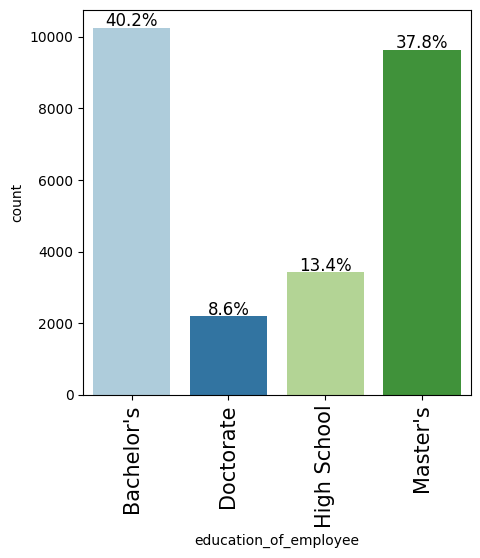

In [ ]:
# education_of_employee barplot
lab_bar(df_copy, 'education_of_employee', perc = True)

A vast majority of the employees have either a bachelor's or a master's as their highest level of education.

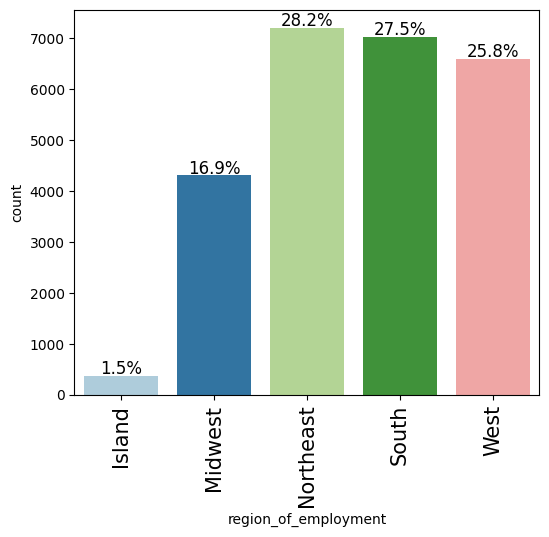

In [ ]:
# region_of_employment barplot
lab_bar(df_copy, 'region_of_employment', perc = True)

A vast majority of employess will be working in either the Northeast, the South, or the West, with a minority in Island.

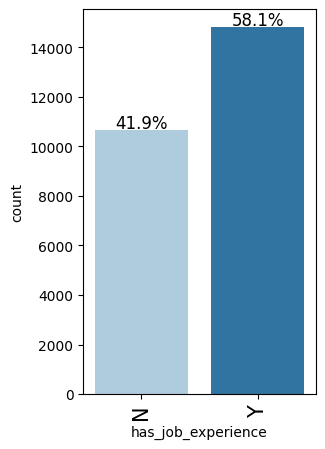

In [ ]:
# has_job_experience barplot
lab_bar(df_copy, 'has_job_experience', perc = True)

58.1% of employees have job experience, while 41.9% do not.

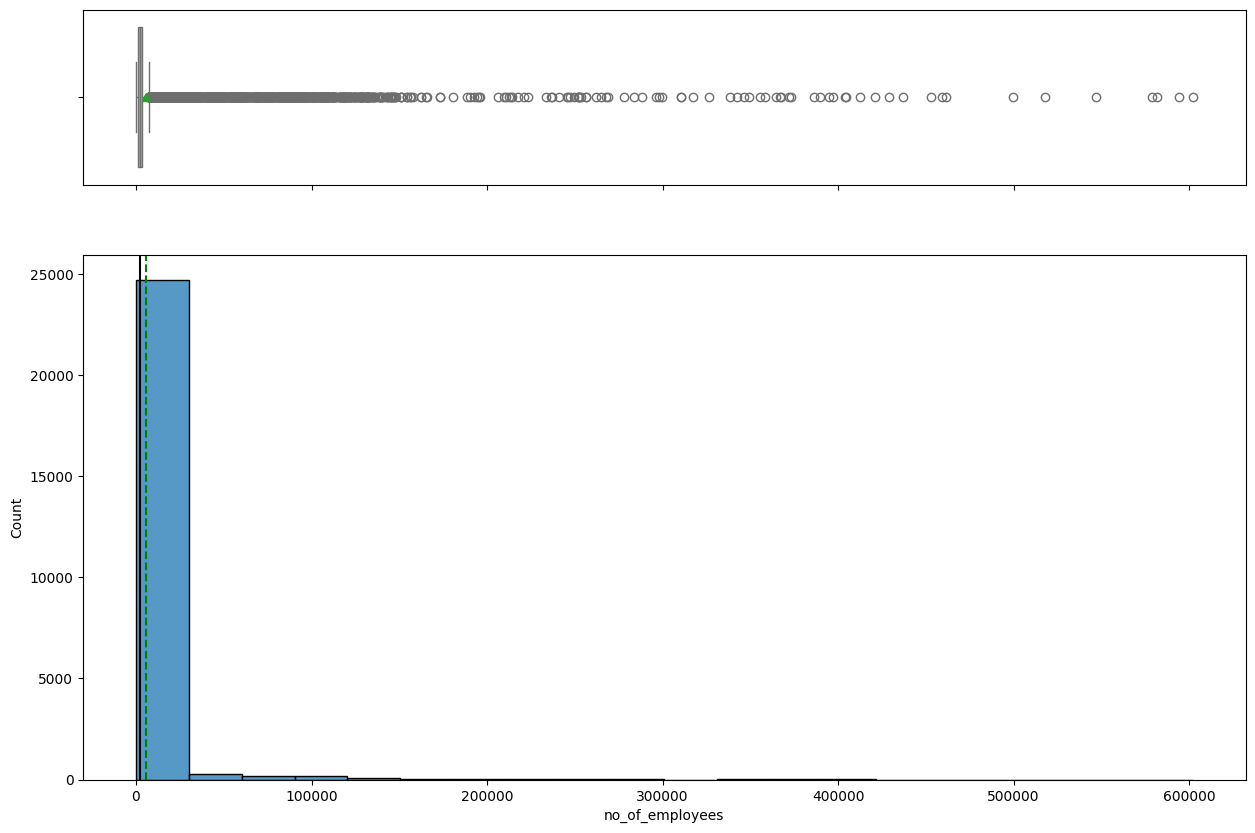

In [ ]:
# no_of_employees histogram and boxplot
hist_box(df_copy, 'no_of_employees', bins = 20)

The distribution for no_of_employees appears to be heavily right-skewed, with numerous outliers to the right.

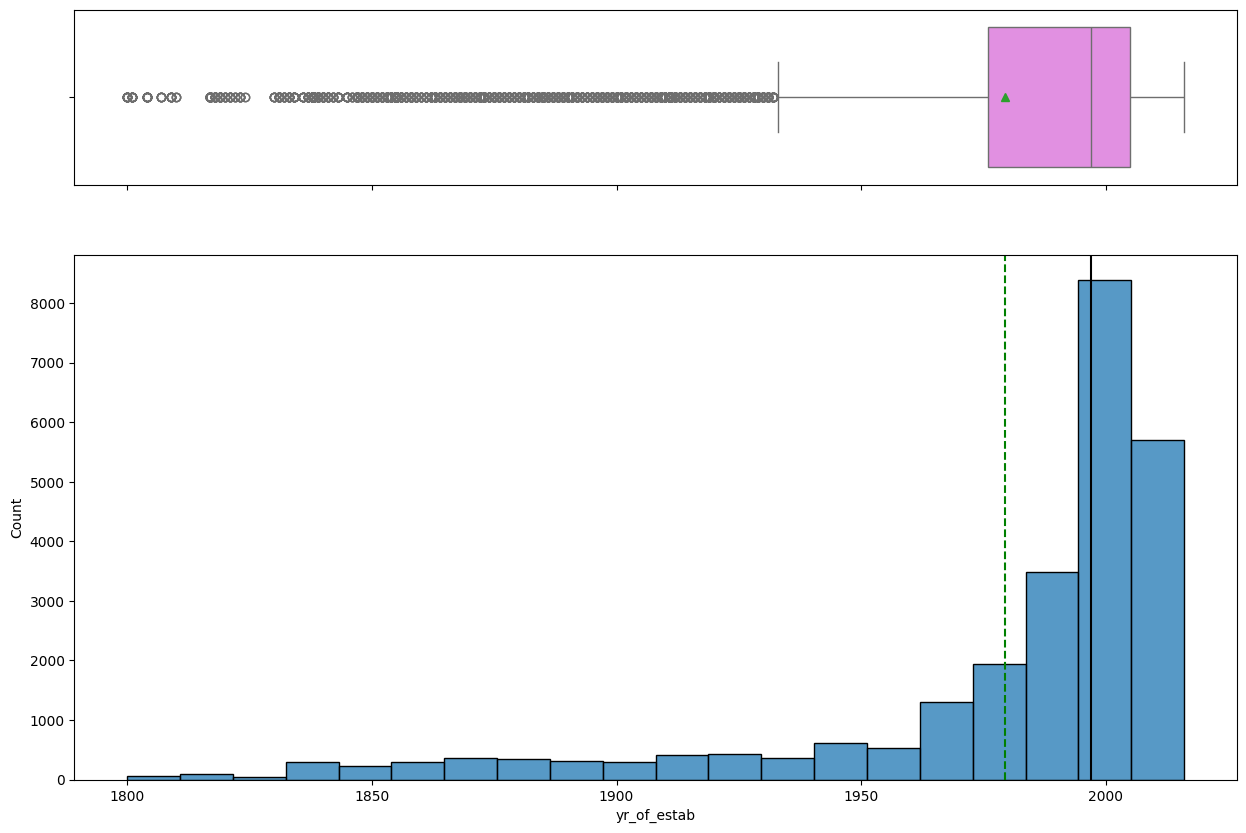

In [ ]:
# yr_of_estab histogram and boxplot
hist_box(df_copy, 'yr_of_estab', bins = 20)

The distribution for yr_of_estab appears to be heavily left-skewed, with numerous outliers to the left.

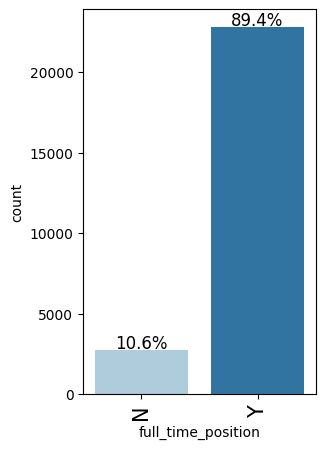

In [ ]:
# full_time_position barplot
lab_bar(df_copy, 'full_time_position', perc = True)

A vast majority are in a full-time position, at 89.4%.

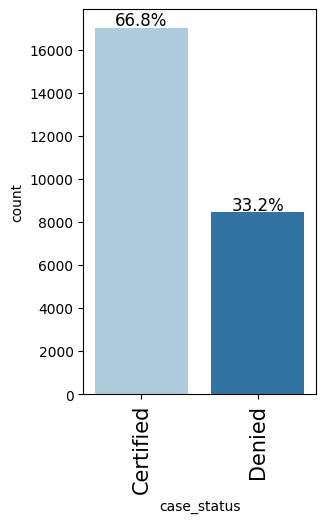

In [ ]:
# case_status barplot
lab_bar(df_copy, 'case_status', perc = True)

66.8% of the visas are certified, while the rest are denied.

# **Bivariate Analysis**

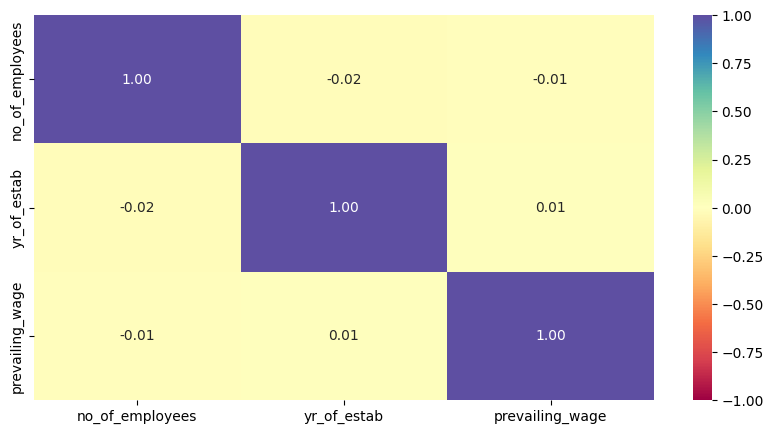

In [ ]:
# The cols as a list or array
cols_list = df_copy.select_dtypes(include = np.number).columns.tolist()

# Plotting the figure
plt.figure(figsize = (10, 5))
sns.heatmap(df_copy[cols_list].corr(), annot = True, vmin = -1, vmax = 1, fmt = '.2f', cmap = 'Spectral')
plt.show()

The correlation between the numeric cols appears to be very weak in both directions.

In [ ]:
# Defining dist_plot_wrt_target function
def dist_plot_wrt_target(data, predictor, target):
  fig, axs = plt.subplots(2, 2, figsize = (12, 10))
  target_uniq = data[target].unique()
  axs[0, 0].set_title('Distribution of target for target = ' + str(target_uniq[0]))
  sns.histplot(
    data = data[data[target] == target_uniq[0]],
    x = predictor,
    kde = True,
    ax = axs[0, 0],
    color = 'teal',
    stat = 'density'
  )
  axs[0, 1].set_title('Distribution of target for target = ' + str(target_uniq[1]))
  sns.histplot(
    data = data[data[target] == target_uniq[1]],
    x = predictor,
    kde = True,
    ax = axs[0, 1],
    color = 'orange',
    stat = 'density'
  )
  axs[1, 0].set_title('Boxplot wrt target')
  sns.boxplot(
    data = data,
    x = target,
    y = predictor,
    ax = axs[1, 0],
    palette = 'gist_rainbow'
  )
  axs[1, 1].set_title('Boxplot (no outliers) wrt target')
  sns.boxplot(
    data = data,
    x = target,
    y = predictor,
    ax = axs[1, 1],
    showfliers = False,
    palette = 'gist_rainbow'
  )
  plt.tight_layout()
  plt.show()

In [ ]:
# Defining stack_bar function
def stack_bar(data, predictor, target):
  count = data[predictor].nunique()
  sorter = data[target].value_counts().index[-1]
  tab1 = pd.crosstab(data[predictor], data[target], margins = True).sort_values(
    by = sorter, ascending = False
  )
  print(tab1)
  print('-' * 120)
  tab = pd.crosstab(data[predictor], data[target], normalize = 'index').sort_values(
    by = sorter, ascending = False
  )
  tab.plot(kind = 'bar', stacked = True, figsize = (count + 5, 5))
  plt.legend(
      loc = 'lower left', frameon = False,
  )
  plt.legend(loc = 'upper left', bbox_to_anchor = (1, 1))
  plt.show()

case_status            Certified  Denied    All
education_of_employee                          
All                        17018    8462  25480
Bachelor's                  6367    3867  10234
High School                 1164    2256   3420
Master's                    7575    2059   9634
Doctorate                   1912     280   2192
------------------------------------------------------------------------------------------------------------------------


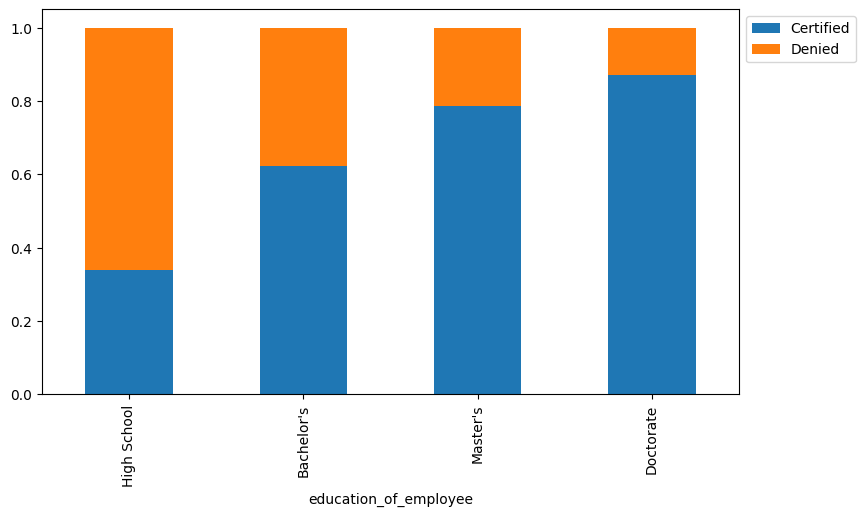

In [ ]:
# Stacked barplot between education_of_employee and case_status
stack_bar(df_copy, 'education_of_employee', 'case_status')

It appears that the higher the education level, the more likely a visa will be certified.

case_status    Certified  Denied    All
continent                              
All                17018    8462  25480
Asia               11012    5849  16861
North America       2037    1255   3292
Europe              2957     775   3732
South America        493     359    852
Africa               397     154    551
Oceania              122      70    192
------------------------------------------------------------------------------------------------------------------------


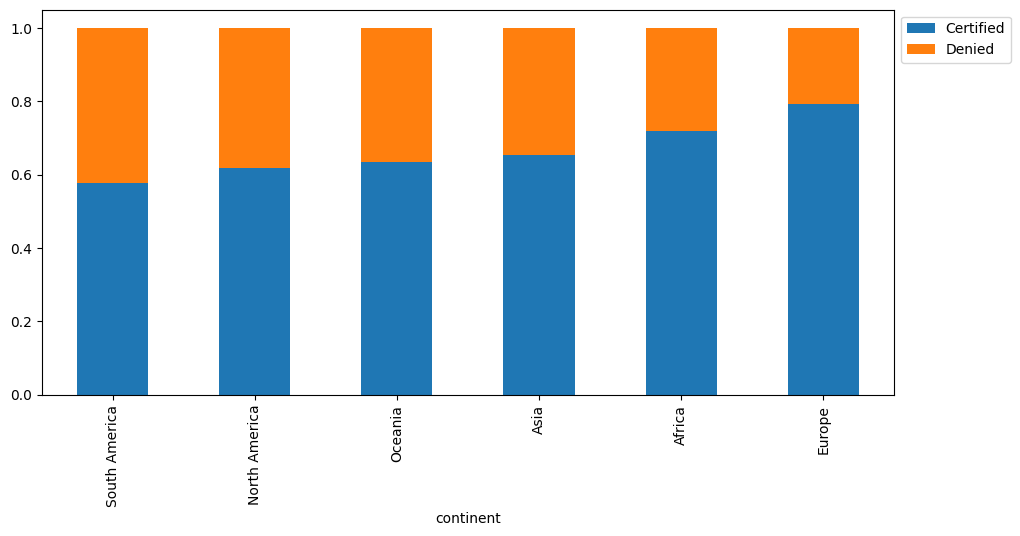

In [ ]:
# Stacked barplot between continent and case_status
stack_bar(df_copy, 'continent', 'case_status')

Visas appear to be more likely to be denied in the Americas, while they appear to be more likely to be certified in Europe.

case_status         Certified  Denied    All
has_job_experience                          
All                     17018    8462  25480
N                        5994    4684  10678
Y                       11024    3778  14802
------------------------------------------------------------------------------------------------------------------------


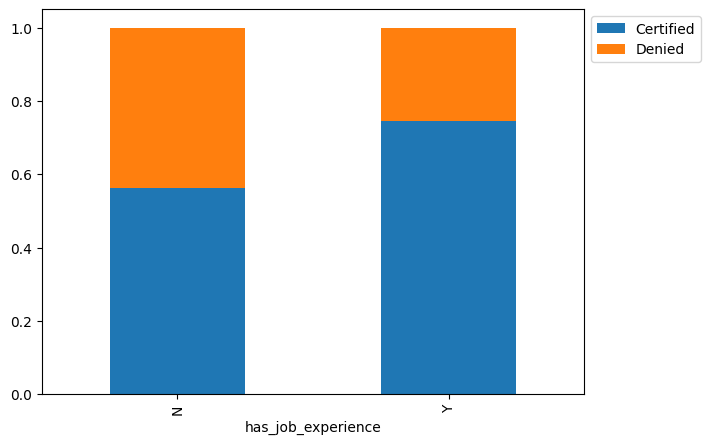

In [ ]:
# Stacked barplot between has_job_experience and case_status
stack_bar(df_copy, 'has_job_experience', 'case_status')

It appears that visas are more likely to be certified if the owner has work experience.

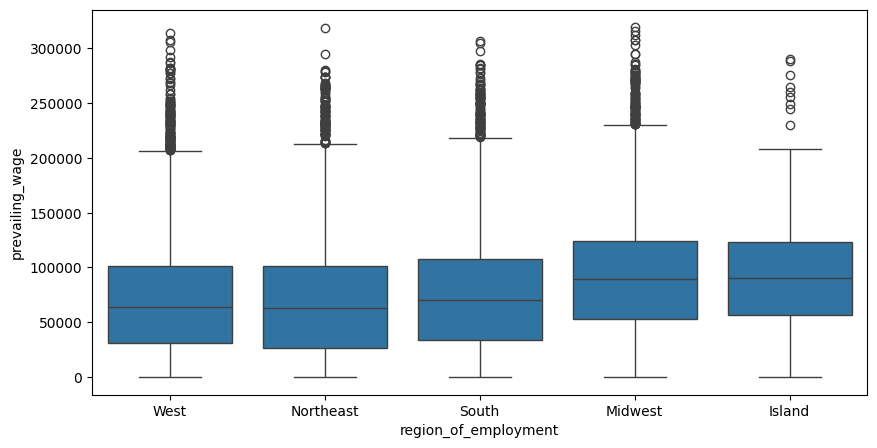

In [ ]:
# Is the prevailing wage similar across all regions of the US?
plt.figure(figsize = (10, 5))
sns.boxplot(data = df_copy, x = 'region_of_employment', y = 'prevailing_wage')
plt.show()

The prevailing wage appears to be similar across the different regions.

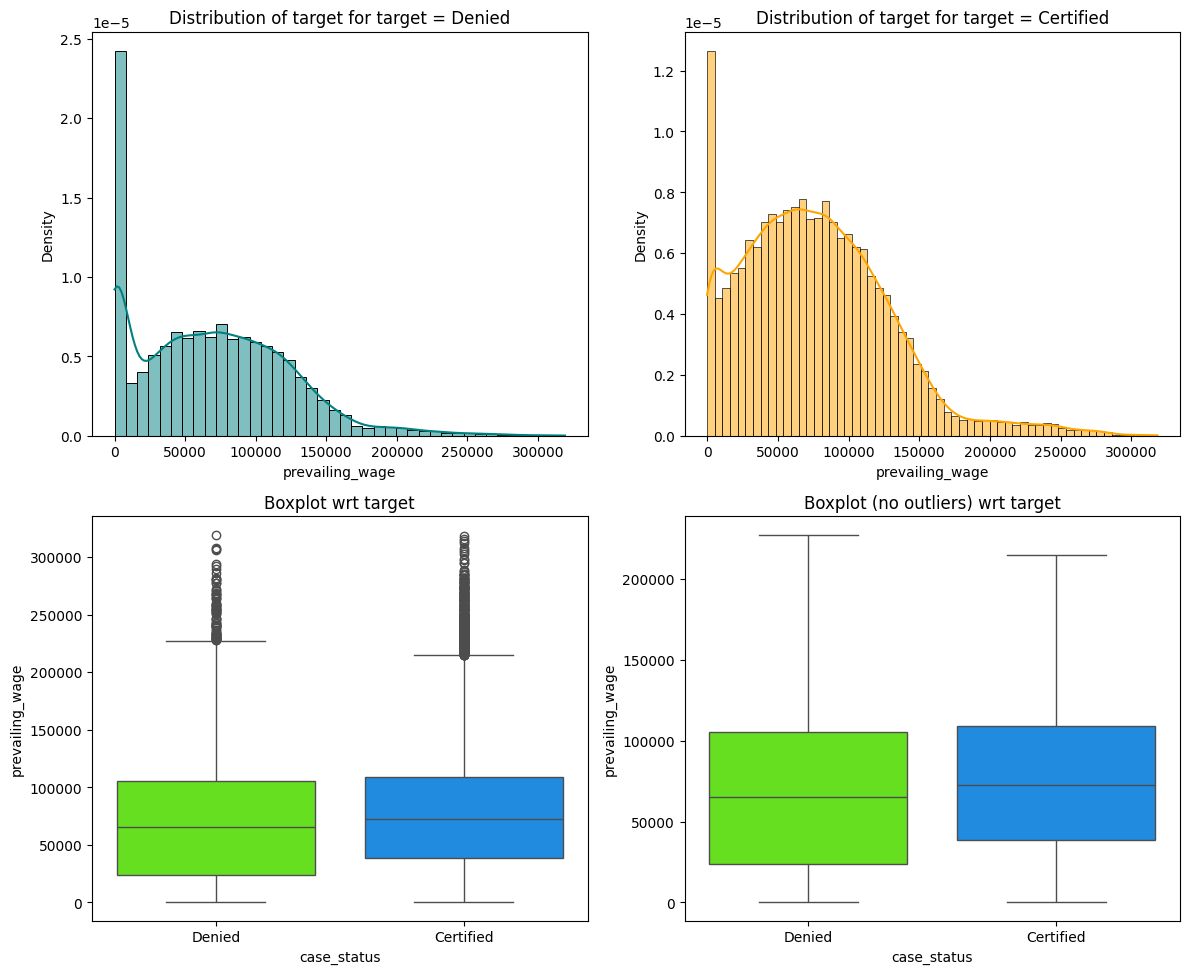

In [ ]:
# Does visa status change with the prevailing wage?
dist_plot_wrt_target(df_copy, 'prevailing_wage', 'case_status')

The distributions appear to be quite similar.

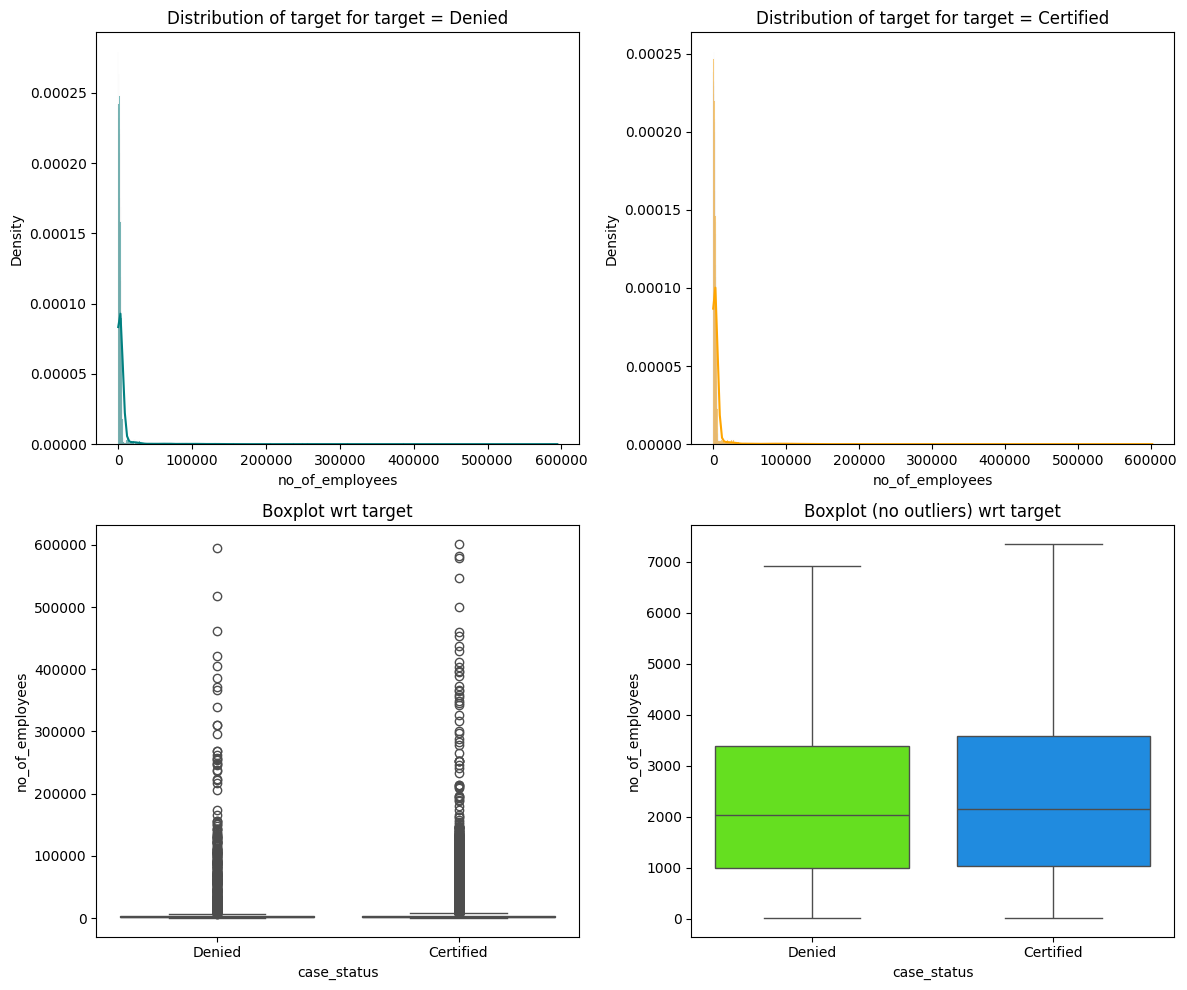

In [ ]:
# Distribution of no_of_employees and case_status
dist_plot_wrt_target(df_copy, 'no_of_employees', 'case_status')

The distributions also appear to be quite similar.

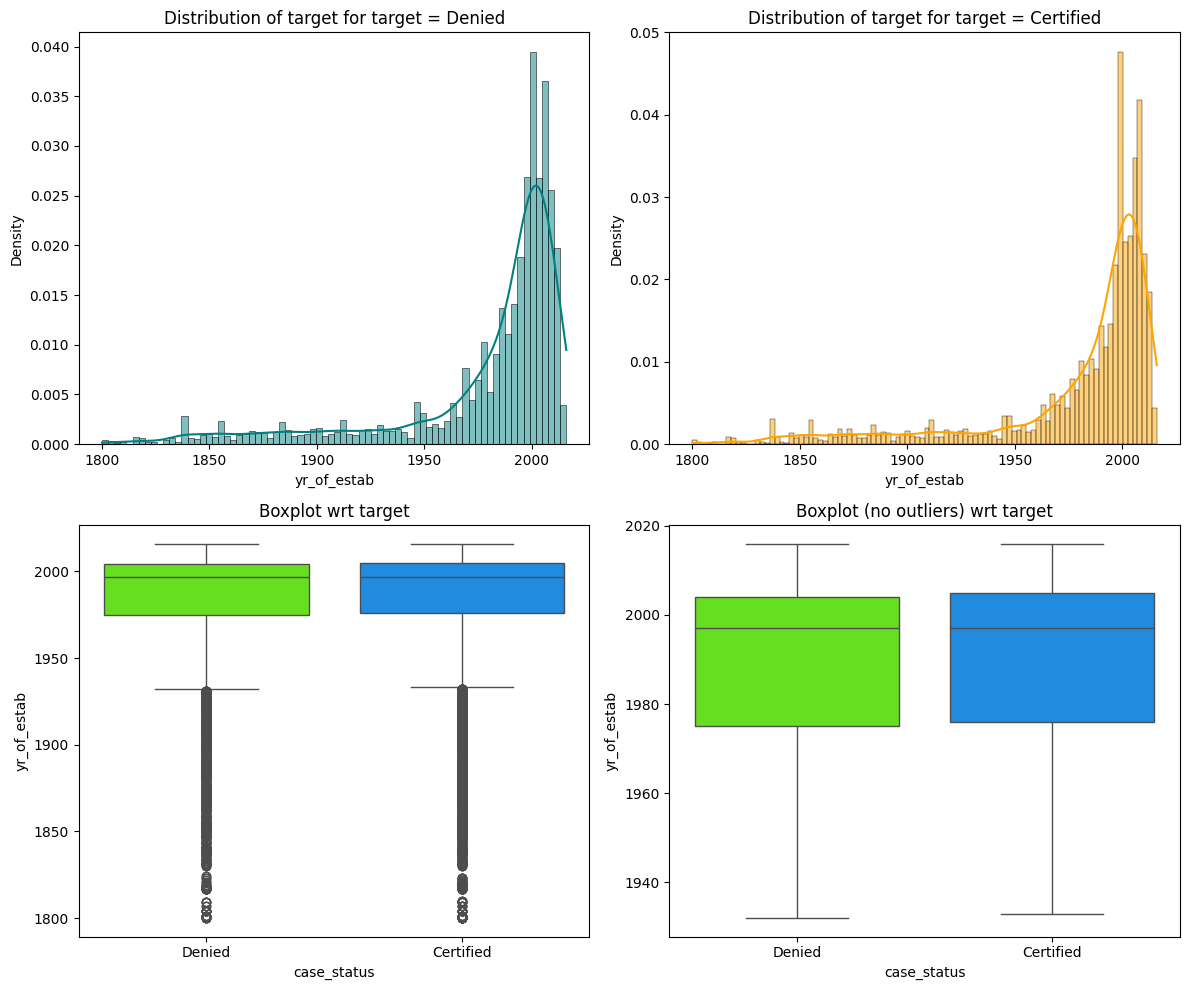

In [ ]:
# Distribution of yr_of_estab and case_status
dist_plot_wrt_target(df_copy, 'yr_of_estab', 'case_status')

The distributions also appear to be quite similar.

case_status   Certified  Denied    All
unit_of_wage                          
All               17018    8462  25480
Year              16047    6915  22962
Hour                747    1410   2157
Week                169     103    272
Month                55      34     89
------------------------------------------------------------------------------------------------------------------------


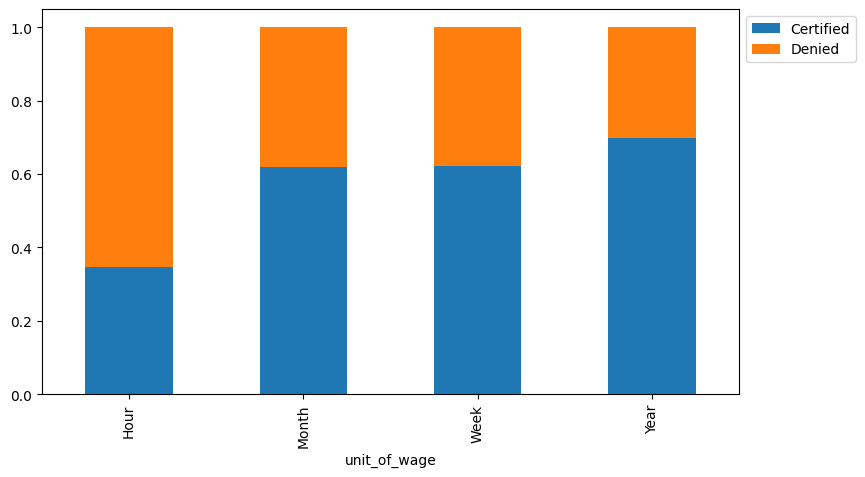

In [ ]:
# Stacked barplot between unit_of_wage and case_status
stack_bar(df_copy, 'unit_of_wage', 'case_status')

The visa is more likely to be denied if the unit of wage is hourly, whereas it is least likely if yearly.

case_status         Certified  Denied    All
full_time_position                          
All                     17018    8462  25480
Y                       15163    7610  22773
N                        1855     852   2707
------------------------------------------------------------------------------------------------------------------------


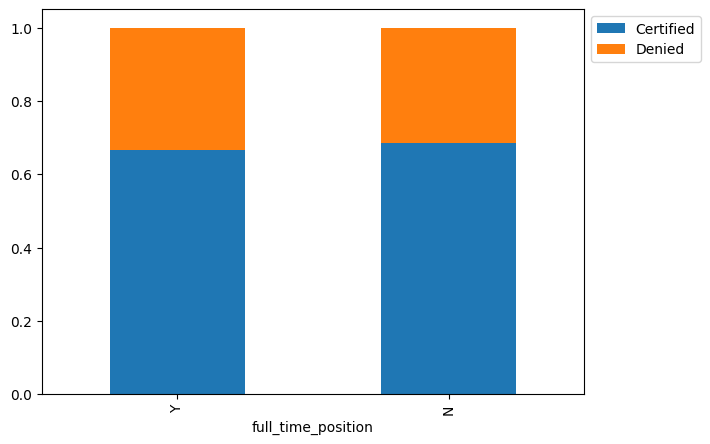

In [ ]:
# Stacked barplot between full_time_position and case_status
stack_bar(df_copy, 'full_time_position', 'case_status')

There appears to be no impact on visa certification in regards to if the worker is in a full-time position or not.

# **Data Pre-processing**

- Missing value treatment (if needed)
- Feature engineering (if needed)
- Outlier detection and treatment (if needed)
- Preparing data for modeling
- Any other preprocessing steps (if needed)

There are no missing values!

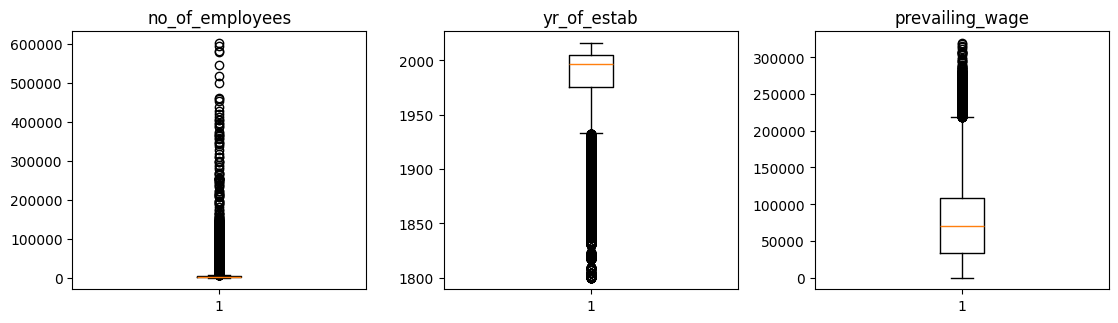

In [ ]:
# Checking for outliers using a boxplot
num_cols = df_copy.select_dtypes(include = np.number).columns.tolist()
plt.figure(figsize = (15, 12))
for i, variable in enumerate(num_cols):
  plt.subplot(4, 4, i + 1)
  plt.boxplot(df_copy[variable], whis = 1.5)
  plt.tight_layout()
  plt.title(variable)
plt.show()

In [ ]:
# Encoding cat cols
df_copy['case_status'] = df_copy['case_status'].apply(lambda x: 1 if x == 'Certified' else 0)

# Creating X and Y
X = df_copy.drop(['case_status'], axis = 1)
Y = df_copy['case_status']
X = pd.get_dummies(X, drop_first = True)
X = X.astype(float)

# Splitting data
X_temp, X_test, Y_Temp, Y_test = train_test_split(X, Y, test_size = 0.2, random_state = 1, stratify = Y)
X_train, X_val, Y_train, Y_val = train_test_split(X_temp, Y_Temp, test_size = 0.25, random_state = 1, stratify = Y_Temp)

In [ ]:
# Printing shapes and % of classes
print('Train shape: ', X_train.shape)
print('Validation shape: ', X_val.shape)
print('Test shape: ', X_test.shape)
print('% of classes in training set:')
print(Y_train.value_counts(normalize = True))
print('% of classes in validation set:')
print(Y_val.value_counts(normalize = True))
print('% of classes in test set:')
print(Y_test.value_counts(normalize = True))

Train shape:  (15288, 21)
Validation shape:  (5096, 21)
Test shape:  (5096, 21)
% of classes in training set:
case_status
1    0.667844
0    0.332156
Name: proportion, dtype: float64
% of classes in validation set:
case_status
1    0.667975
0    0.332025
Name: proportion, dtype: float64
% of classes in test set:
case_status
1    0.667975
0    0.332025
Name: proportion, dtype: float64


# **Model Building**

In [ ]:
# The model_perform_class function
def model_perform_class(model, predictors, target):
  # Predicting using the independent variables
  pred = model.predict(predictors)

  # Computing accuracy, recall, precision, and f1
  acc = accuracy_score(target, pred)
  recall = recall_score(target, pred)
  precision = precision_score(target, pred)
  f1 = f1_score(target, pred)

  # A dataframe of metrics
  perf = pd.DataFrame(
    {"Accuracy": acc, "Recall": recall, "Precision": precision, "F1": f1,},
    index=[0],
  )

  return perf

In [ ]:
# The my_confusion_matrix function
def my_confusion_matrix(model, predictors, target):
  y_pred = model.predict(predictors)
  cm = confusion_matrix(target, y_pred)
  labels = np.asarray(
    [
      ["{0:0.0f}".format(item) + "\n{0:.2%}".format(item / cm.flatten().sum())]
      for item in cm.flatten()
    ]
  ).reshape(2, 2)

  plt.figure(figsize = (6, 4))
  sns.heatmap(cm, annot = labels, fmt = "")
  plt.ylabel("True label")
  plt.xlabel("Predicted label")

In [ ]:
# Model building for the original data
models = []

# Appending models
models.append(('Bagging', BaggingClassifier(random_state = 1)))
models.append(('Random Forest', RandomForestClassifier(random_state = 1, class_weight = 'balanced')))
models.append(('Ada Boost', AdaBoostClassifier(random_state = 1)))
models.append(('Gradient Boosting', GradientBoostingClassifier(random_state = 1)))
models.append(('Stacking', StackingClassifier(estimators = models)))

# The training data's performance
print('\nTraining Data Performance:\n')
for name, model in models:
  model.fit(X_train, Y_train)
  scores = f1_score(Y_train, model.predict(X_train))
  print('{}: {}'.format(name, scores))

# The validation data's performance
print('\nValidation Data Performance:\n')
for name, model in models:
  model.fit(X_train, Y_train)
  scores_val = f1_score(Y_val, model.predict(X_val))
  print('{}: {}'.format(name, scores_val))


Training Data Performance:

Bagging: 0.989150179193873
Random Forest: 1.0
Ada Boost: 0.8204269947530306
Gradient Boosting: 0.8291218182658106


RecursionError: maximum recursion depth exceeded

Random forest seems to perform the best for the training data.

In [ ]:
# Model building for oversampled data
print('Before Oversampling for Certified: {}'.format(sum(Y_train == 1)))
print('Before Oversampling for Denied: {}'.format(sum(Y_train == 0)))

# Oversampling
sm = SMOTE(sampling_strategy = 1, k_neighbors = 5, random_state = 1)
X_train_over, Y_train_over = sm.fit_resample(X_train, Y_train)

print('After Oversampling for Certified: {}'.format(sum(Y_train_over == 1)))
print('After Oversampling for Denied: {}'.format(sum(Y_train_over == 0)))

Before Oversampling for Certified: 10210
Before Oversampling for Denied: 5078
After Oversampling for Certified: 10210
After Oversampling for Denied: 10210


In [ ]:
models = []

# Appending models
models.append(('Bagging', BaggingClassifier(random_state = 1)))
models.append(('Random Forest', RandomForestClassifier(random_state = 1)))
models.append(('Ada Boost', AdaBoostClassifier(random_state = 1)))
models.append(('Gradient Boosting', GradientBoostingClassifier(random_state = 1)))
models.append(('Stacking', StackingClassifier(estimators = models)))

# The training data's performance
print('\nTraining Data Performance:\n')
for name, model in models:
  model.fit(X_train_over, Y_train_over)
  scores = f1_score(Y_train_over, model.predict(X_train_over))
  print('{}: {}'.format(name, scores))

# The validation data's performance
print('\nValidation Data Performance:\n')
for name, model in models:
  model.fit(X_train_over, Y_train_over)
  scores_val = f1_score(Y_val, model.predict(X_val))
  print('{}: {}'.format(name, scores_val))


Training Data Performance:

Bagging: 0.988462860228779
Random Forest: 0.9999510308016257
Ada Boost: 0.8133627829928216
Gradient Boosting: 0.8209709101113086


RecursionError: maximum recursion depth exceeded

Random forest seems to perform the best for the training data.

In [ ]:
# Model building for undersampled data
rus = RandomUnderSampler(random_state = 1)
X_train_under, Y_train_under = rus.fit_resample(X_train, Y_train)

# Before and after Undersampling
print('Before Undersampling for Certified: {}'.format(sum(Y_train == 1)))
print('Before Undersampling for Denied: {}'.format(sum(Y_train == 0)))
print('After Undersampling for Certified: {}'.format(sum(Y_train_under == 1)))
print('After Undersampling for Denied: {}'.format(sum(Y_train_under == 0)))

# The shapes
print('After Undersampling X_train Shape: {}'.format(X_train_under.shape))
print('After Undersampling Y_train Shape: {}'.format(Y_train_under.shape))

Before Undersampling for Certified: 10210
Before Undersampling for Denied: 5078
After Undersampling for Certified: 5078
After Undersampling for Denied: 5078
After Undersampling X_train Shape: (10156, 21)
After Undersampling Y_train Shape: (10156,)


In [ ]:
models = []

# Appending models
models.append(('Bagging', BaggingClassifier(random_state = 1)))
models.append(('Random Forest', RandomForestClassifier(random_state = 1)))
models.append(('Ada Boost', AdaBoostClassifier(random_state = 1)))
models.append(('Gradient Boosting', GradientBoostingClassifier(random_state = 1)))
models.append(('Stacking', StackingClassifier(estimators = models)))

# The training data's performance
print('\nTraining Data Performance:\n')
for name, model in models:
  model.fit(X_train_under, Y_train_under)
  scores = f1_score(Y_train_under, model.predict(X_train_under))
  print('{}: {}'.format(name, scores))

# The validation data's performance
print('\nValidation Data Performance:\n')
for name, model in models:
  model.fit(X_train_under, Y_train_under)
  scores_val = f1_score(Y_val, model.predict(X_val))
  print('{}: {}'.format(name, scores_val))


Training Data Performance:

Bagging: 0.9803687095166915
Random Forest: 1.0
Ada Boost: 0.7015343047380103
Gradient Boosting: 0.7281441717791411


RecursionError: maximum recursion depth exceeded

Random forest seems to perform the best for the training data.

# **Model Performance Improvement**

## **Note**

1. Sample parameter grids have been provided to do necessary hyperparameter tuning. These sample grids are expected to provide a balance between model performance improvement and execution time. One can extend/reduce the parameter grid based on execution time and system configuration.
  - Please note that if the parameter grid is extended to improve the model performance further, the execution time will increase
2. The models chosen in this notebook are based on test runs. One can update the best models as obtained upon code execution and tune them for best performance.

- For Gradient Boosting:

```
param_grid = {
    "init": [AdaBoostClassifier(random_state=1),DecisionTreeClassifier(random_state=1)],
    "n_estimators": np.arange(50,110,25),
    "learning_rate": [0.01,0.1,0.05],
    "subsample":[0.7,0.9],
    "max_features":[0.5,0.7,1],
}
```

- For Adaboost:

```
param_grid = {
    "n_estimators": np.arange(50,110,25),
    "learning_rate": [0.01,0.1,0.05],
    "base_estimator": [
        DecisionTreeClassifier(max_depth=2, random_state=1),
        DecisionTreeClassifier(max_depth=3, random_state=1),
    ],
}
```

- For Bagging Classifier:

```
param_grid = {
    'max_samples': [0.8,0.9,1],
    'max_features': [0.7,0.8,0.9],
    'n_estimators' : [30,50,70],
}
```
- For Random Forest:

```
param_grid = {
    "n_estimators": [50,110,25],
    "min_samples_leaf": np.arange(1, 4),
    "max_features": [np.arange(0.3, 0.6, 0.1),'sqrt'],
    "max_samples": np.arange(0.4, 0.7, 0.1)
}
```

- For Decision Trees:

```
param_grid = {
    'max_depth': np.arange(2,6),
    'min_samples_leaf': [1, 4, 7],
    'max_leaf_nodes' : [10, 15],
    'min_impurity_decrease': [0.0001,0.001]
}
```

- For XGBoost:

```
param_grid={'n_estimators':np.arange(50,110,25),
            'scale_pos_weight':[1,2,5],
            'learning_rate':[0.01,0.1,0.05],
            'gamma':[1,3],
            'subsample':[0.7,0.9]
}
```


In [ ]:
%%time
import sklearn.metrics

# Hyperparameter tuning for random forest
rf_tuned = RandomForestClassifier(random_state = 1, oob_score = True, bootstrap = True)

# The params
params = {
    'max_depth': list(np.arange(5, 15, 5)),
    'max_features': ['sqrt', 'log2'],
    'min_samples_split': [3, 5, 7],
    'n_estimators': np.arange(10, 40, 10),
}

# Scoring for comparison
acc_scorer = sklearn.metrics.make_scorer(sklearn.metrics.f1_score)

# Grid search
grid_obj = GridSearchCV(rf_tuned, params, scoring = acc_scorer, cv = 5, n_jobs = -1)
grid_obj = grid_obj.fit(X_train_over, Y_train_over)

# Setting clf to best combo of params
rf_tuned = grid_obj.best_estimator_

# Fitting best algorithm
rf_tuned.fit(X_train, Y_train)

CPU times: user 2.52 s, sys: 258 ms, total: 2.78 s
Wall time: 57.6 s


RandomForestClassifier(max_depth=np.int64(10), min_samples_split=5,
                       n_estimators=np.int64(20), oob_score=True,
                       random_state=1)

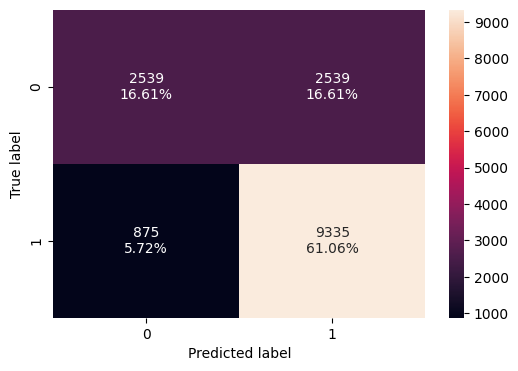

In [ ]:
# Model performance on training set
my_confusion_matrix(rf_tuned, X_train, Y_train)

In [ ]:
rf_tuned_model_train_perf = model_perform_class(rf_tuned, X_train, Y_train)
rf_tuned_model_train_perf

,Accuracy,Recall,Precision,F1
0,0.776688,0.9143,0.786171,0.845408


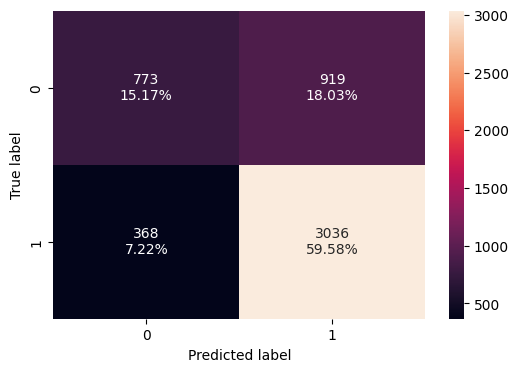

In [ ]:
# Model performance on validation set
my_confusion_matrix(rf_tuned, X_val, Y_val)

In [ ]:
rf_tuned_model_val_perf = model_perform_class(rf_tuned, X_val, Y_val)
rf_tuned_model_val_perf

,Accuracy,Recall,Precision,F1
0,0.747449,0.891892,0.767636,0.825112


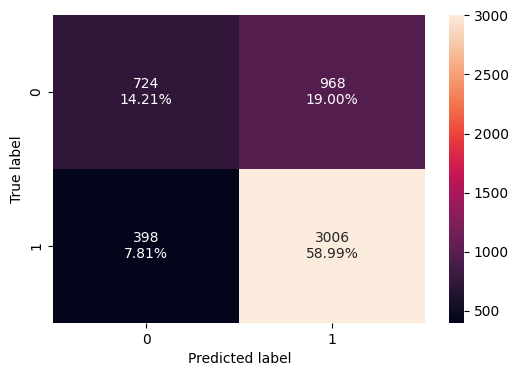

In [ ]:
# Model performance on test set
my_confusion_matrix(rf_tuned, X_test, Y_test)

In [ ]:
rf_tuned_model_test_perf = model_perform_class(rf_tuned, X_test, Y_test)
rf_tuned_model_test_perf

,Accuracy,Recall,Precision,F1
0,0.731947,0.883079,0.756417,0.814855


In [ ]:
%%time
import sklearn.metrics

# Hyperparameter tuning for AdaBoost
abc_tuned = AdaBoostClassifier(random_state = 1)

# The params
params = {
    'estimator': [
        DecisionTreeClassifier(max_depth = 2, random_state = 1),
        DecisionTreeClassifier(max_depth = 3, random_state = 1),
    ],
    'n_estimators': np.arange(50, 110, 25),
    'learning_rate': [0.01, 0.1, 0.05],
}

# Scoring for comparison
acc_scorer = sklearn.metrics.make_scorer(sklearn.metrics.f1_score)

# Grid search
grid_obj = GridSearchCV(abc_tuned, params, scoring = acc_scorer, cv = 5, n_jobs = -1)
grid_obj = grid_obj.fit(X_train_over, Y_train_over)

# Setting clf to best combo of params
abc_tuned = grid_obj.best_estimator_

# Fitting best algorithm
abc_tuned.fit(X_train, Y_train)

CPU times: user 10.8 s, sys: 304 ms, total: 11.1 s
Wall time: 3min 49s


AdaBoostClassifier(estimator=DecisionTreeClassifier(max_depth=3,
                                                    random_state=1),
                   learning_rate=0.1, n_estimators=np.int64(100),
                   random_state=1)

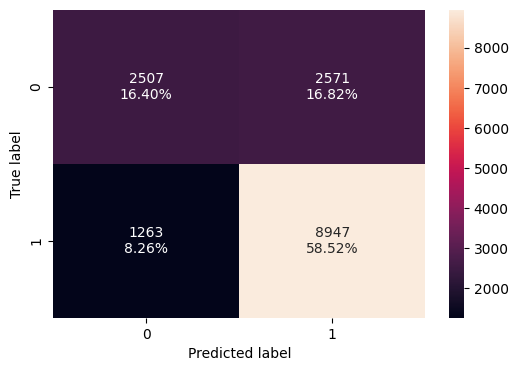

In [ ]:
# Model performance on training set
my_confusion_matrix(abc_tuned, X_train, Y_train)

In [ ]:
abc_tuned_model_train_perf = model_perform_class(abc_tuned, X_train, Y_train)
abc_tuned_model_train_perf

,Accuracy,Recall,Precision,F1
0,0.749215,0.876298,0.776784,0.823546


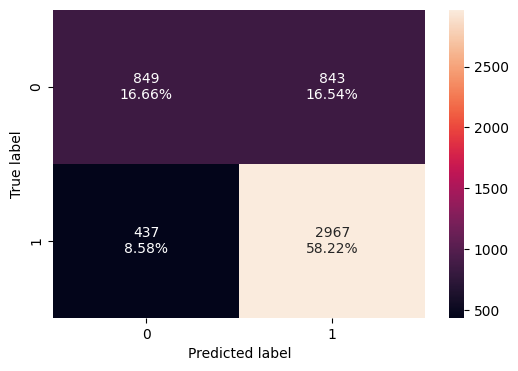

In [ ]:
# Model performance on validation set
my_confusion_matrix(abc_tuned, X_val, Y_val)

In [ ]:
abc_tuned_model_val_perf = model_perform_class(abc_tuned, X_val, Y_val)
abc_tuned_model_val_perf

,Accuracy,Recall,Precision,F1
0,0.748823,0.871622,0.77874,0.822567


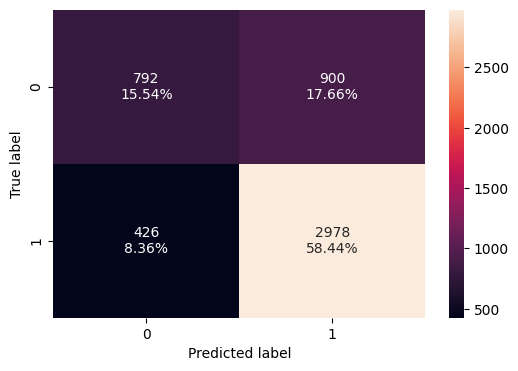

In [ ]:
# Model performance on test set
my_confusion_matrix(abc_tuned, X_test, Y_test)

In [ ]:
abc_tuned_model_test_perf = model_perform_class(abc_tuned, X_test, Y_test)
abc_tuned_model_test_perf

,Accuracy,Recall,Precision,F1
0,0.739796,0.874853,0.767922,0.817907


In [ ]:
%%time
import sklearn.metrics

# Hyperparameter tuning for Gradient Boost
gbc_tuned = GradientBoostingClassifier(init = AdaBoostClassifier(random_state = 1), random_state = 1)

# The params
params = {
    'n_estimators': np.arange(50, 110, 25),
    'subsample': [0.7, 0.9],
    'max_features': [0.7, 0.8, 0.9, 1.0],
    'learning_rate': [0.01, 0.1, 0.05],
}

# Scoring for comparison
acc_scorer = sklearn.metrics.make_scorer(sklearn.metrics.f1_score)

# Grid search
grid_obj = GridSearchCV(gbc_tuned, params, scoring = acc_scorer, cv = 5, n_jobs = -1)
grid_obj = grid_obj.fit(X_train_over, Y_train_over)

# Setting clf to best combo of params
gbc_tuned = grid_obj.best_estimator_

# Fitting best algorithm
gbc_tuned.fit(X_train, Y_train)

CPU times: user 14.2 s, sys: 1.21 s, total: 15.4 s
Wall time: 16min 8s


GradientBoostingClassifier(init=AdaBoostClassifier(random_state=1),
                           max_features=0.7, n_estimators=np.int64(100),
                           random_state=1, subsample=0.9)

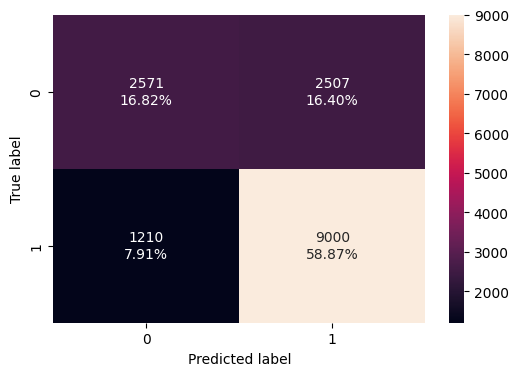

In [ ]:
# Model performance on training set
my_confusion_matrix(gbc_tuned, X_train, Y_train)

In [ ]:
gbc_tuned_model_train_perf = model_perform_class(gbc_tuned, X_train, Y_train)
gbc_tuned_model_train_perf

,Accuracy,Recall,Precision,F1
0,0.756868,0.881489,0.782133,0.828844


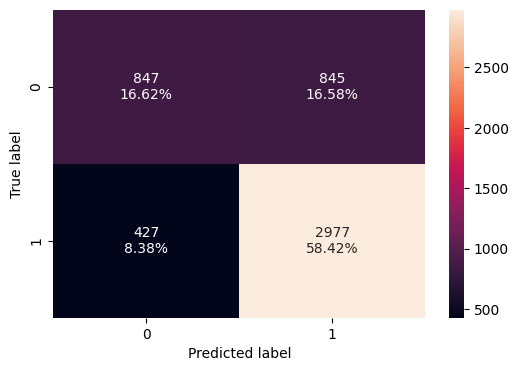

In [ ]:
# Model performance on validation set
my_confusion_matrix(gbc_tuned, X_val, Y_val)

In [ ]:
gbc_tuned_model_val_perf = model_perform_class(gbc_tuned, X_val, Y_val)
gbc_tuned_model_val_perf

,Accuracy,Recall,Precision,F1
0,0.750392,0.874559,0.778912,0.823969


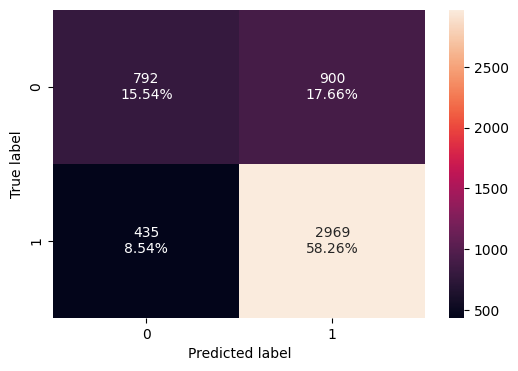

In [ ]:
# Model performance on test set
my_confusion_matrix(gbc_tuned, X_test, Y_test)

In [ ]:
gbc_tuned_model_test_perf = model_perform_class(gbc_tuned, X_test, Y_test)
gbc_tuned_model_test_perf

,Accuracy,Recall,Precision,F1
0,0.73803,0.872209,0.767382,0.816444


In [ ]:
%%time
import sklearn.metrics

# Hyperparameter tuning for XGBoosting
xgb_tuned = XGBClassifier(random_state = 1, eval_metric = 'logloss')

# The params
params = {
    'n_estimators': np.arange(50, 110, 25),
    'scale_pos_weight': [1, 2, 5],
    'subsample': [0.9, 1.0],
    'learning_rate': [0.01, 0.1, 0.05],
    'gamma': [1, 3],
}

# Scoring for comparison
acc_scorer = sklearn.metrics.make_scorer(sklearn.metrics.f1_score)

# Grid search
grid_obj = GridSearchCV(xgb_tuned, params, scoring = acc_scorer, cv = 5, n_jobs = -1)
grid_obj = grid_obj.fit(X_train_over, Y_train_over)

# Setting clf to best combo of params
xgb_tuned = grid_obj.best_estimator_

# Fitting best algorithm
xgb_tuned.fit(X_train, Y_train)

CPU times: user 8.76 s, sys: 840 ms, total: 9.6 s
Wall time: 4min 47s


XGBClassifier(base_score=None, booster=None, callbacks=None,
              colsample_bylevel=None, colsample_bynode=None,
              colsample_bytree=None, device=None, early_stopping_rounds=None,
              enable_categorical=False, eval_metric='logloss',
              feature_types=None, feature_weights=None, gamma=3,
              grow_policy=None, importance_type=None,
              interaction_constraints=None, learning_rate=0.1, max_bin=None,
              max_cat_threshold=None, max_cat_to_onehot=None,
              max_delta_step=None, max_depth=None, max_leaves=None,
              min_child_weight=None, missing=nan, monotone_constraints=None,
              multi_strategy=None, n_estimators=np.int64(100), n_jobs=None,
              num_parallel_tree=None, ...)

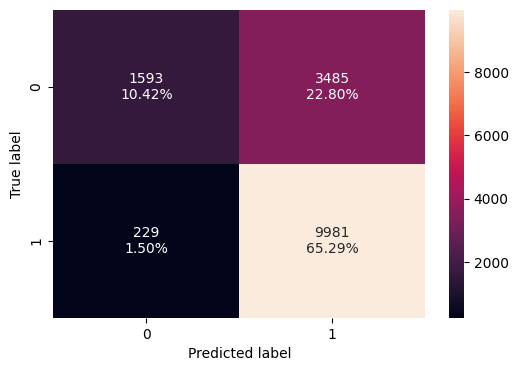

In [ ]:
# Model performance on training set
my_confusion_matrix(xgb_tuned, X_train, Y_train)

In [ ]:
xgb_tuned_model_train_perf = model_perform_class(xgb_tuned, X_train, Y_train)
xgb_tuned_model_train_perf

,Accuracy,Recall,Precision,F1
0,0.757064,0.977571,0.7412,0.843132


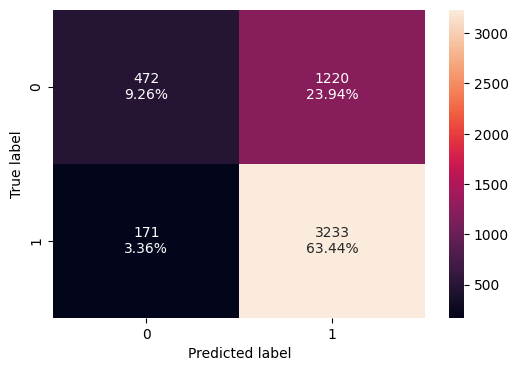

In [ ]:
# Model performance on validation set
my_confusion_matrix(xgb_tuned, X_val, Y_val)

In [ ]:
xgb_tuned_model_val_perf = model_perform_class(xgb_tuned, X_val, Y_val)
xgb_tuned_model_val_perf

,Accuracy,Recall,Precision,F1
0,0.727041,0.949765,0.726027,0.82296


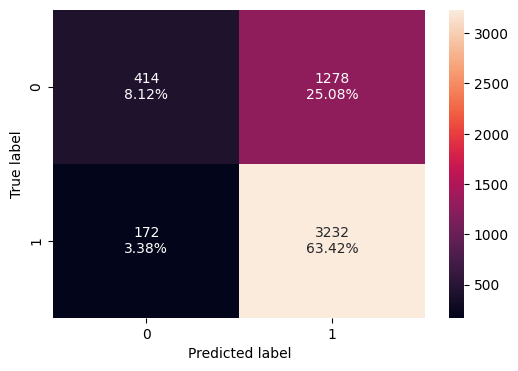

In [ ]:
# Model performance on test set
my_confusion_matrix(xgb_tuned, X_test, Y_test)

In [ ]:
xgb_tuned_model_test_perf = model_perform_class(xgb_tuned, X_test, Y_test)
xgb_tuned_model_test_perf

,Accuracy,Recall,Precision,F1
0,0.715463,0.949471,0.71663,0.81678


# **Model Comparison and Final Model Selection**

In [ ]:
# Training performance comparison
models_train_comp_df = pd.concat(
    [rf_tuned_model_train_perf.T, abc_tuned_model_train_perf.T, gbc_tuned_model_train_perf.T, xgb_tuned_model_train_perf.T], axis = 1,
)
models_train_comp_df.columns = ["Tuned Random Forest", "Tuned Adaboost", "Tuned Gradient Boost", "Tuned XGBoost"]
print("Training performance comparison:")
models_train_comp_df

Training performance comparison:


,Tuned Random Forest,Tuned Adaboost,Tuned Gradient Boost,Tuned XGBoost
Accuracy,0.776688,0.749215,0.756868,0.757064
Recall,0.914300,0.876298,0.881489,0.977571
Precision,0.786171,0.776784,0.782133,0.741200
F1,0.845408,0.823546,0.828844,0.843132


In [ ]:
# Validation performance comparison
models_val_comp_df = pd.concat(
    [rf_tuned_model_val_perf.T, abc_tuned_model_val_perf.T, gbc_tuned_model_val_perf.T, xgb_tuned_model_val_perf.T], axis = 1,
)
models_val_comp_df.columns = ["Tuned Random Forest", "Tuned Adaboost", "Tuned Gradient Boost", "Tuned XGBoost"]
print("Training performance comparison:")
models_val_comp_df

Training performance comparison:


,Tuned Random Forest,Tuned Adaboost,Tuned Gradient Boost,Tuned XGBoost
Accuracy,0.747449,0.748823,0.750392,0.727041
Recall,0.891892,0.871622,0.874559,0.949765
Precision,0.767636,0.778740,0.778912,0.726027
F1,0.825112,0.822567,0.823969,0.822960


In [ ]:
# Test performance comparison
models_test_comp_df = pd.concat(
    [rf_tuned_model_test_perf.T, abc_tuned_model_test_perf.T, gbc_tuned_model_test_perf.T, xgb_tuned_model_test_perf.T], axis = 1,
)
models_test_comp_df.columns = ["Tuned Random Forest", "Tuned Adaboost", "Tuned Gradient Boost", "Tuned XGBoost"]
print("Training performance comparison:")
models_test_comp_df

Training performance comparison:


,Tuned Random Forest,Tuned Adaboost,Tuned Gradient Boost,Tuned XGBoost
Accuracy,0.731947,0.739796,0.738030,0.715463
Recall,0.883079,0.874853,0.872209,0.949471
Precision,0.756417,0.767922,0.767382,0.716630
F1,0.814855,0.817907,0.816444,0.816780


Across all sets, XGBoost appears to perform the best.

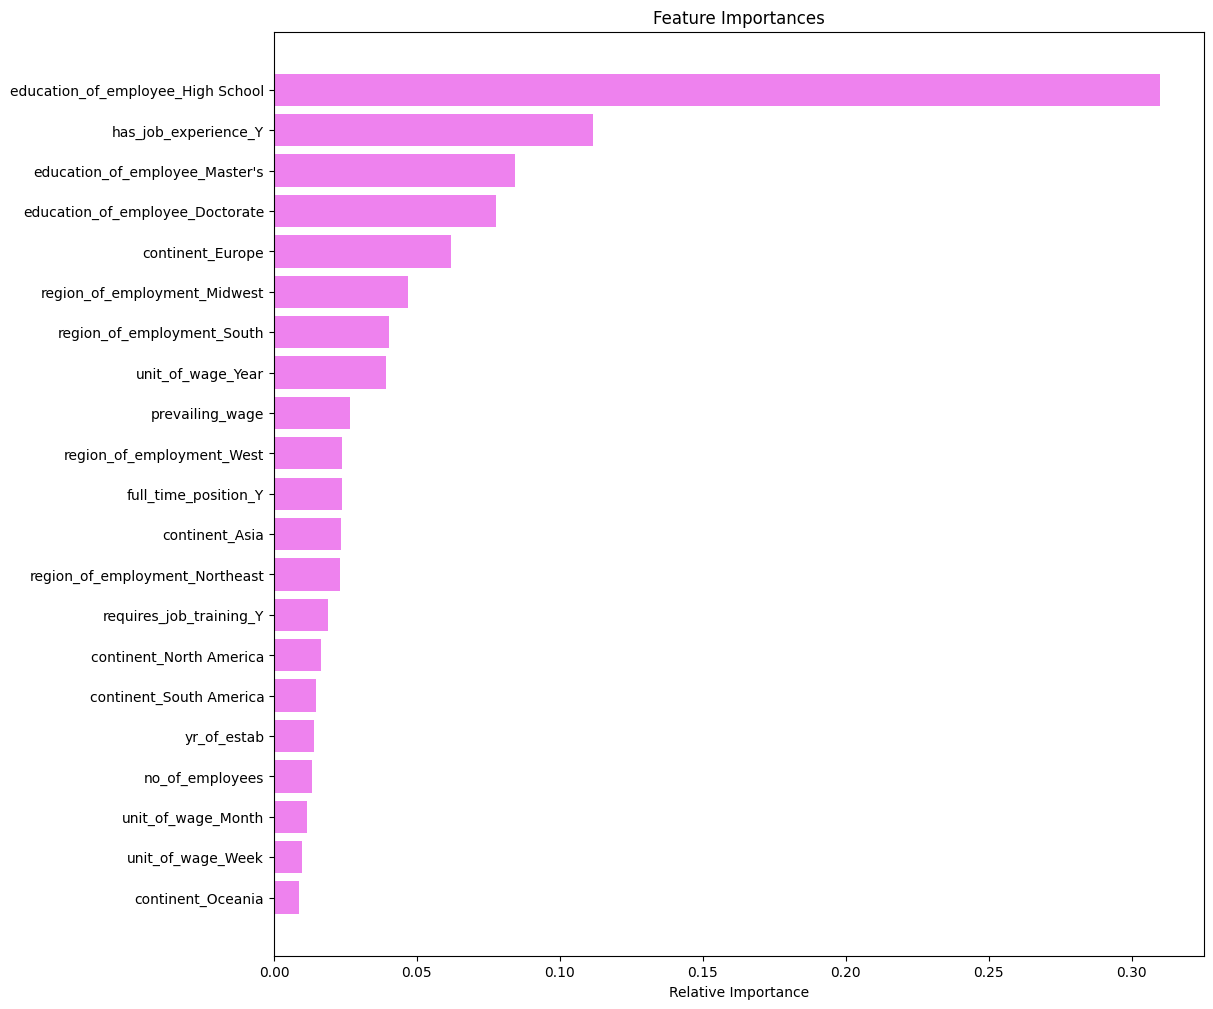

In [ ]:
# Important features
feature_names = X_train.columns
importances = xgb_tuned.feature_importances_
indices = np.argsort(importances)

plt.figure(figsize = (12, 12))
plt.title('Feature Importances')
plt.barh(range(len(indices)), importances[indices], color = 'violet', align = 'center')
plt.yticks(range(len(indices)), [feature_names[i] for i in indices])
plt.xlabel('Relative Importance')
plt.show()

The most important feature is the education of the employee, followed by job experience.

# **Actionable Insights and Recommendations**

The employee's education level, particularly if they have a high school education or higher, appears to be the most important feature, as shown on the graph. An earlier graph also shows that those with an education level higher than high school are more likely to be certified than denied. The OFLC can aim for more certified employees by giving employees with only high school educations incentives towards getting a higher education.

___